Introduccion

El metodo Welch es una herramienta para el estimar de la densidad espectral de potencia de una señal. Se basa en dividir la señal en bloques de tiempo, calcular el periodograma de cada uno, realizar promedios y los solapa. En esta Tarea Semanal se aplico este metodo para tres señales distintas, haciendo pruebas con distinta cantidad de particiones y promedios de la señal con el objetivo de minimizar el ruido de la misma, es decir, relizar un diagrama espectral de potencia con menor varianza. 

Desarrollo

Señal de audio
\\Se realizaron cuatro estimaciones de la densidad espectral de potencia con el metodo de Welch partiendo la señal en dos, treinta, cincuenta y cien bloques. Se eligio, para calcular el ancho de banda, la estimacion con treinta bloques ya que en mi criterio era la que tenia mejor balance entre menor varianza y menor sesgo de la señal. Con esta estimacion se calculo el ancho de banda de la señal buscando el valor de frecuencia hasta el cual la señal acumulaba el 99% de su potencia. Se obtuvo como resultado un ancho de banda de 2020Hz.

Ancho de banda (99% de la potencia de la señal): 2020.0


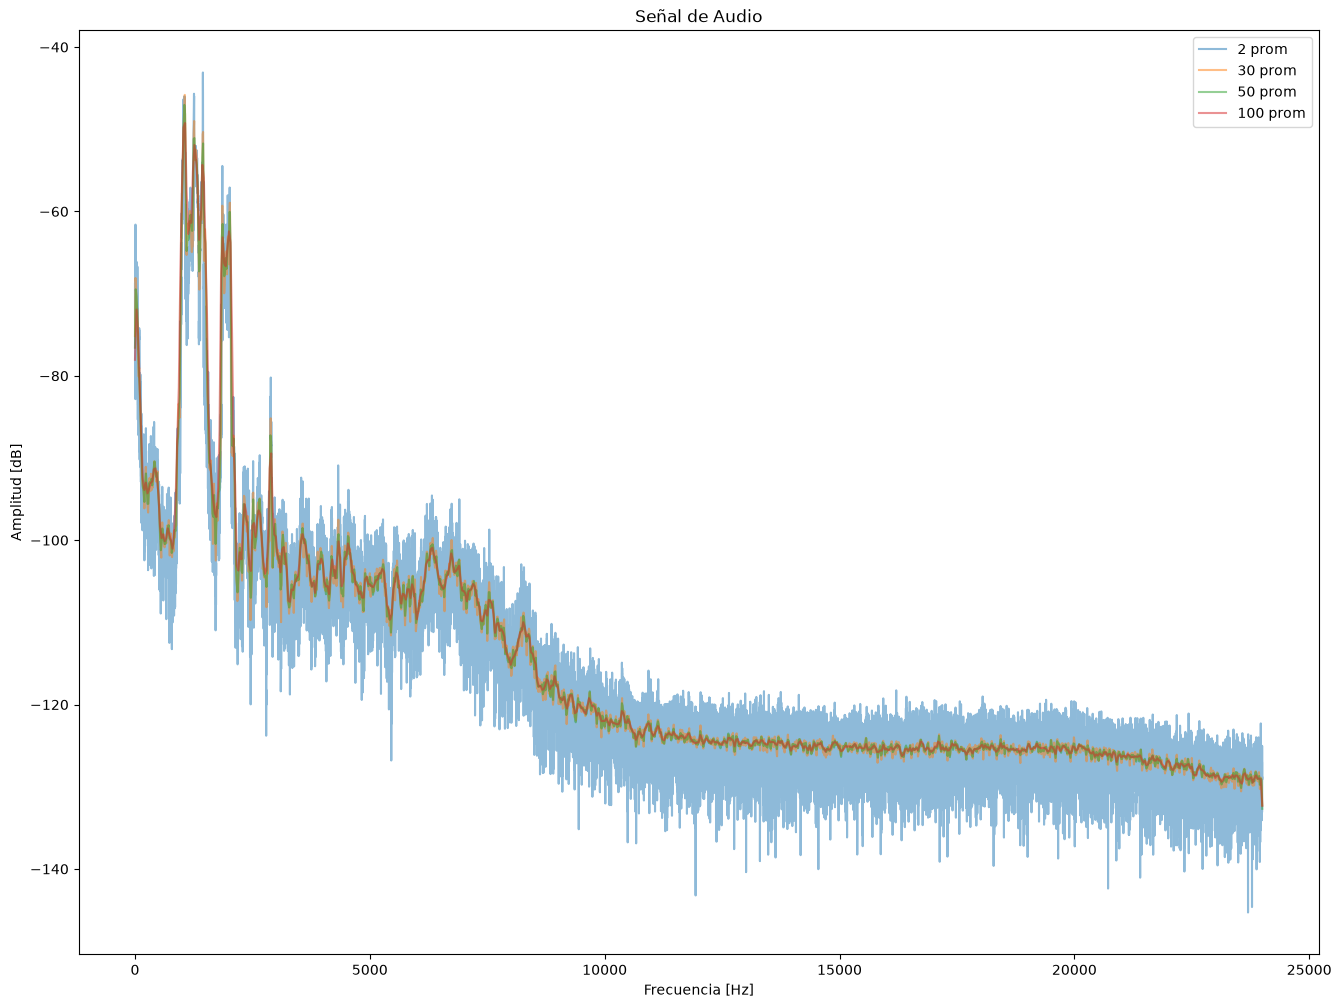

In [1]:
import numpy as np
import scipy as sp
import scipy.io as sio
import matplotlib.pyplot as plt


# =============================================================================
# importo el archivo de audio
# =============================================================================
fs_audio, wav_data = sio.wavfile.read('la cucaracha.wav')
#fs_audio, wav_data = sio.wavfile.read('prueba psd.wav')
#fs_audio, wav_data = sio.wavfile.read('silbido.wav') 
# plt.figure(1)
# plt.plot(wav_data)

frec_2, wav_data_wel_2 = sp.signal.welch(wav_data, fs_audio, nperseg=len(wav_data)//2) #densidad espectar de frecuencia con 2 promedios
frec_30, wav_data_wel_30 = sp.signal.welch(wav_data, fs_audio, nperseg=len(wav_data)//30) #densidad espectar de frecuencia con 30 promedios
frec_50, wav_data_wel_50 = sp.signal.welch(wav_data, fs_audio, nperseg=len(wav_data)//50)
frec_100, wav_data_wel_100 = sp.signal.welch(wav_data, fs_audio, nperseg=len(wav_data)//100)

modulo_wav_db_2 = 10* np.log10(wav_data_wel_2)   # 2 promedios
modulo_wav_db_30 = 10* np.log10(wav_data_wel_30) # 30 promedios
modulo_wav_db_50 = 10* np.log10(wav_data_wel_50) # 50 promedios
modulo_wav_db_100 = 10* np.log10(wav_data_wel_100) # 100 promedios

#ancho de banda
pot_acum_wav_norm = np.cumsum(wav_data_wel_30)/(np.cumsum(wav_data_wel_30)[-1]) #calculo la suma total de la densidad de potencia y la normalizo
idx = np.searchsorted(pot_acum_wav_norm , 0.99)
bw = frec_30[idx]
print(f'Ancho de banda (99% de la potencia de la señal): {bw}')

plt.figure(2, figsize=(16,12))
plt.title("Señal de Audio")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud [dB]")
plt.plot(frec_2, modulo_wav_db_2, alpha=0.5, label='2 prom')
plt.plot(frec_30, modulo_wav_db_30, alpha=0.5, label='30 prom')
plt.plot(frec_50, modulo_wav_db_50, alpha=0.5, label='50 prom')
plt.plot(frec_100, modulo_wav_db_100, alpha=0.5, label='100 prom')
plt.legend(loc='upper right')
plt.show()

Señal de ppg (fotopletismografía)

Para esta señal se realizaron tambien cuatro estimaciones partiendo la señal en dos, siete, diez y veinte bloques y se realizo el calculo de ancho de banda con la estimacion de 10 promedios por el mismo motivo que en la señal anterior. Cabe destacar que en este caso se realizaron menos particiones de la señal para encontrar el balance entre sesgo y varianza. El ancho de banda calculado fue de 4Hz. 

ancho de banda (95% de la potencia de la señal): 3.9189490091293697


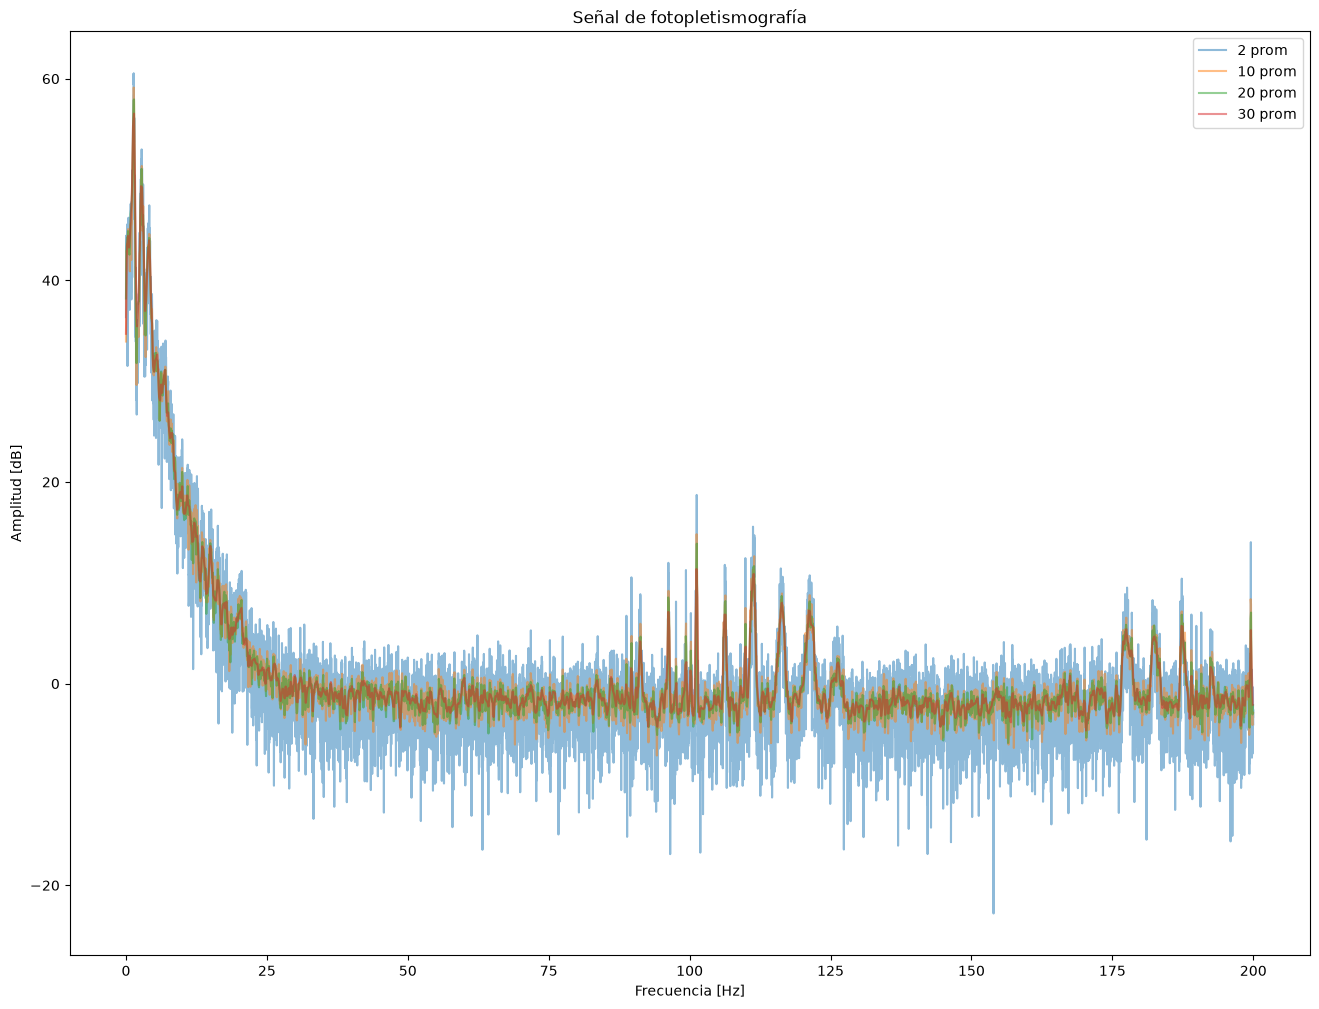

In [2]:
# =============================================================================
# importo el archivo ppg
# =============================================================================
ppg = np.load('ppg_sin_ruido.npy')
fs_ppg = 400 #Hz
# plt.figure(3)
# plt.plot(ppg)

f_ppg_2, ppg_wel_2 = sp.signal.welch(ppg, fs_ppg, nperseg=len(ppg)//2) #densidad espectar de frecuencia con 2 promedios
f_ppg_10, ppg_wel_10 = sp.signal.welch(ppg, fs_ppg, nperseg=len(ppg)//7) #densidad espectar de frecuencia con 7 promedios
f_ppg_20, ppg_wel_20 = sp.signal.welch(ppg, fs_ppg, nperseg=len(ppg)//10)
f_ppg_30, ppg_wel_30 = sp.signal.welch(ppg, fs_ppg, nperseg=len(ppg)//20)

modulo_ppg_db_2 = 10* np.log10((ppg_wel_2))   # 2 promedios
modulo_ppg_db_10 = 10* np.log10((ppg_wel_10)) # 10 promedios
modulo_ppg_db_20 = 10* np.log10((ppg_wel_20)) # 20 promedios
modulo_ppg_db_30 = 10* np.log10((ppg_wel_30)) # 30 promedios

#ancho de banda
pot_acum_ppg_norm = np.cumsum(ppg_wel_20)/(np.cumsum(ppg_wel_20)[-1]) #calculo la suma total de la densidad de potencia y la normalizo
idx = np.searchsorted(pot_acum_ppg_norm , 0.95)
bw = f_ppg_20[idx]
print(f'ancho de banda (95% de la potencia de la señal): {bw}')

plt.figure(4, figsize=(16,12))
plt.title("Señal de fotopletismografía")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud [dB]")
plt.plot(f_ppg_2, modulo_ppg_db_2, alpha=0.5, label='2 prom')
plt.plot(f_ppg_10, modulo_ppg_db_10, alpha=0.5, label='10 prom')
plt.plot(f_ppg_20, modulo_ppg_db_20, alpha=0.5, label='20 prom')
plt.plot(f_ppg_30, modulo_ppg_db_30, alpha=0.5, label='30 prom')
plt.legend(loc='upper right')
plt.show()

Señal de epg (electrocardiograma)

Para esta señal se realizaron tambien cuatro estimaciones partiendo la señal en dos, siete, diez y veinte bloques y se realizo el calculo de ancho de banda con la estimacion de 10 promedios. En este caso tambien se realizaron menos particiones de la señal para encontrar el balance entre sesgo y varianza. El ancho de banda calculado fue de aproximadamente 22Hz.

ancho de banda (95% de la potencia de la señal): 22.666666666666664


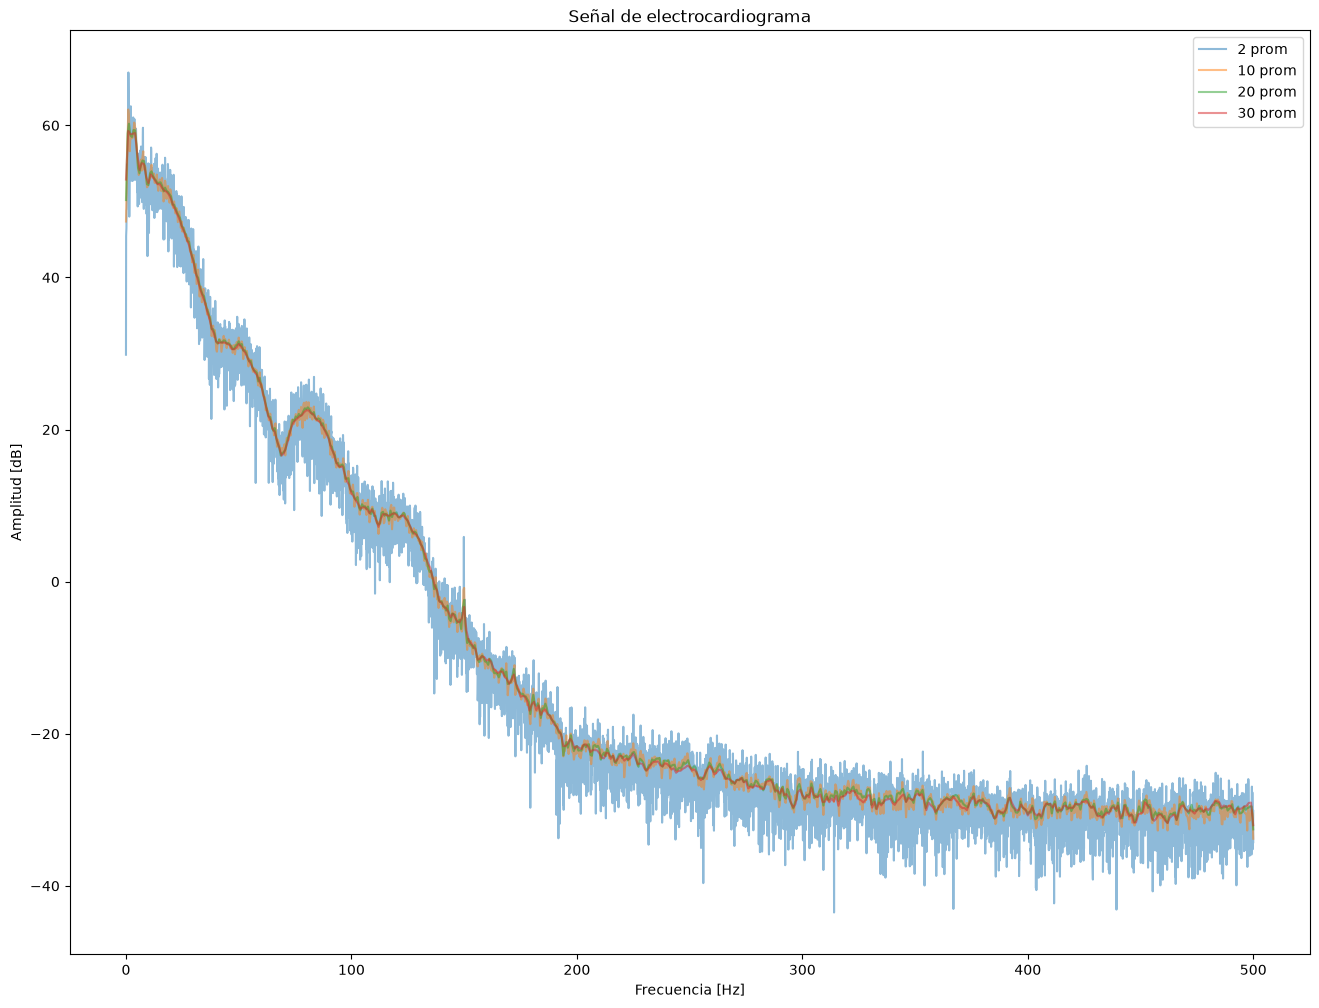

In [3]:
# =============================================================================
# importo el archivo ecg
# =============================================================================
ecg = np.load('ecg_sin_ruido.npy')
fs_ecg = 1000 # Hz
# plt.figure(5)
# plt.plot(ecg)

f_ecg_2, ecg_wel_2 = sp.signal.welch(ecg, fs_ecg, nperseg=len(ecg)//2) #densidad espectar de frecuencia con 2 promedios
f_ecg_10, ecg_wel_10 = sp.signal.welch(ecg, fs_ecg, nperseg=len(ecg)//10) #densidad espectar de frecuencia con 10 promedios
f_ecg_20, ecg_wel_20 = sp.signal.welch(ecg, fs_ecg, nperseg=len(ecg)//20)
f_ecg_30, ecg_wel_30 = sp.signal.welch(ecg, fs_ecg, nperseg=len(ecg)//30)

modulo_ecg_db_2 = 10* np.log10((ecg_wel_2))   # 2 promedios
modulo_ecg_db_10 = 10* np.log10((ecg_wel_10)) # 10 promedios
modulo_ecg_db_20 = 10* np.log10((ecg_wel_20)) # 20 promedios
modulo_ecg_db_30 = 10* np.log10((ecg_wel_30)) # 30 promedios

#ancho de banda
pot_acum_ecg_norm = np.cumsum(ecg_wel_10)/(np.cumsum(ecg_wel_10)[-1]) #calculo la suma total de la densidad de potencia y la normalizo
idx = np.searchsorted(pot_acum_ecg_norm , 0.95)
bw = f_ecg_10[idx]
print(f'ancho de banda (95% de la potencia de la señal): {bw}')

plt.figure(6, figsize=(16,12))
plt.title("Señal de electrocardiograma")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud [dB]")
plt.plot(f_ecg_2, modulo_ecg_db_2, alpha=0.5, label='2 prom')
plt.plot(f_ecg_10, modulo_ecg_db_10, alpha=0.5, label='10 prom')
plt.plot(f_ecg_20, modulo_ecg_db_20, alpha=0.5, label='20 prom')
plt.plot(f_ecg_30, modulo_ecg_db_30, alpha=0.5, label='30 prom')
plt.legend(loc='upper right')
plt.show()

Conclusion 

La herramienta de promediar periodogramas del estimador de Welch efectivamente reduce la varianza de la medicion pero si se divide la señal demasiado, es decir, se aumenta la cantidad de promedios que se relizan para calcular la densidad espectral de potencia, tambien aumenta el sesgo de dicha estimacion. Por eso es necesario realizar varias estimaciones con distinta cantidad de promedios para encontrar un balance entre sesgo y varianza para analizar la señal de manera adecuada. El aumento de promedios hará que la curva se suavice y se reduzca el area bajo la misma. Como concecuencia, el calculo de potencia tendra como resultado un valor mayor al real. 